Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

Load Dataset

In [2]:
df = pd.read_csv("FakeNewsNet.csv")

df = df.dropna(subset=['title', 'real'])

X = df['title'].astype(str)
y = df['real'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Create SVM Pipeline

In [3]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=5000)),
    ('classifier', SVC())
])

Optimize Kernel and Regularization Parameters

In [5]:
param_grid = {
    'classifier__C': [0.1, 1, 10],
    'classifier__kernel': ['linear', 'rbf'],
    'classifier__gamma': ['scale']
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search.best_score_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Parameters:
{'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}

Best Cross-Validation Accuracy:
0.8375188608799541


Evaluate the Best Model

In [6]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Fake News', 'Real News']
))

Test Accuracy: 0.8452586206896552

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.74      0.58      0.65      1151
   Real News       0.87      0.93      0.90      3489

    accuracy                           0.85      4640
   macro avg       0.81      0.76      0.77      4640
weighted avg       0.84      0.85      0.84      4640



Confusion Matrix

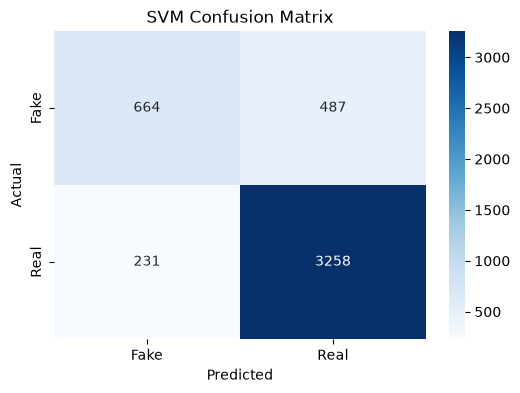

In [7]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fake', 'Real'],
    yticklabels=['Fake', 'Real']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")
plt.show()

Compare Kernel Performance

param_classifier__kernel
linear    0.837088
rbf       0.837519
Name: mean_test_score, dtype: float64


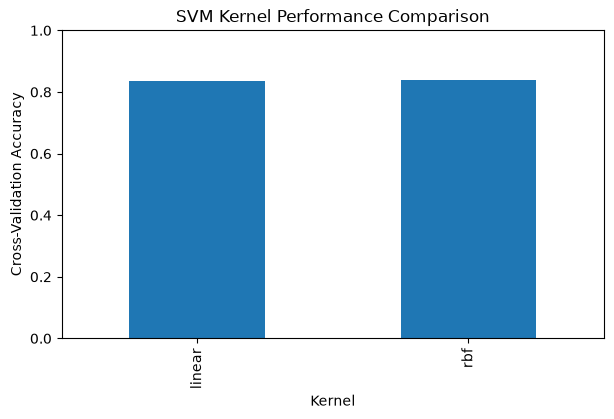

In [8]:
results = pd.DataFrame(grid_search.cv_results_)

kernel_results = results.groupby(
    'param_classifier__kernel'
)['mean_test_score'].max()

print(kernel_results)

kernel_results.plot(kind='bar', figsize=(7, 4))
plt.title("SVM Kernel Performance Comparison")
plt.xlabel("Kernel")
plt.ylabel("Cross-Validation Accuracy")
plt.ylim(0, 1)
plt.show()